# U-Net : Convolutional Networks for Biomedical Image Segmentation
**Reproduction pédagogique de Ronneberger, Fischer & Brox (2015) — arXiv:1505.04597**

Ce notebook implémente, en PyTorch, les éléments clés du papier :

1. l'**architecture U-Net** (convolutions *valid*, recadrage des *skip connections*, 23 couches convolutives) ;
2. la **carte de poids** de la fonction de perte pour séparer les cellules qui se touchent (éq. 2 du papier) ;
3. la **data augmentation par déformations élastiques** (grille 3×3, σ = 10 px, interpolation bicubique) ;
4. l'**initialisation de He**, le **SGD à batch = 1 avec momentum 0,99** ;
5. la stratégie de **overlap-tile** avec extrapolation par miroir pour segmenter des images de taille arbitraire.


In [4]:
!pip install torch torchvision scikit-image scipy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import time, math, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from skimage.segmentation import find_boundaries

warnings.filterwarnings("ignore")
torch.set_num_threads(1)
SEED = 0
rng_global = np.random.default_rng(SEED)
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| device : CPU")

PyTorch 2.15.0+cpu | device : CPU


## 1. Architecture

- **Chemin contractant** : répétition de deux convolutions 3×3 *non paddées* (+ ReLU) puis max-pooling 2×2 stride 2 ; le nombre de canaux double à chaque étape.
- **Chemin expansif** : up-convolution 2×2 (divise les canaux par 2), **concaténation avec la carte de caractéristiques recadrée** du chemin contractant, puis deux convolutions 3×3 + ReLU.
- **Couche finale** : convolution 1×1 vers le nombre de classes.
- Pas de couche entièrement connectée ; *dropout* en fin de chemin contractant ; initialisation de He (écart-type √(2/N)).

In [ ]:
def center_crop(t, h, w):
    dh, dw = (t.shape[2] - h) // 2, (t.shape[3] - w) // 2
    return t[:, :, dh:dh + h, dw:dw + w]

class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=0), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=0), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64, depth=4, dropout=0.5):
        super().__init__()
        chs = [base * 2**i for i in range(depth + 1)]          
        self.down = nn.ModuleList()
        c = in_ch
        for ch in chs[:-1]:
            self.down.append(DoubleConv(c, ch)); c = ch
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout2d(dropout)
        self.bottom = DoubleConv(chs[-2], chs[-1])
        self.up = nn.ModuleList(); self.dec = nn.ModuleList()
        for ch in reversed(chs[:-1]):
            self.up.append(nn.ConvTranspose2d(ch * 2, ch, 2, stride=2))   
            self.dec.append(DoubleConv(ch * 2, ch))
        self.head = nn.Conv2d(chs[0], n_classes, 1)
        for m in self.modules():                                         
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                n_in = m.weight.shape[1] * m.weight.shape[2] * m.weight.shape[3] if isinstance(m, nn.Conv2d) \
                       else m.weight.shape[0] * m.weight.shape[2] * m.weight.shape[3]
                nn.init.normal_(m.weight, 0, math.sqrt(2.0 / n_in)); nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = self.pool(x)
        x = self.drop(x)                      
        x = self.bottom(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            x = torch.cat([center_crop(s, x.shape[2], x.shape[3]), x], dim=1)  
            x = dec(x)
        return self.head(x)

def n_conv_layers(model):
    return sum(isinstance(m, nn.Conv2d) for m in model.modules())

def n_params(model): return sum(p.numel() for p in model.parameters())

### Vérification sur la configuration exacte du papier ( entrée 572×572 → sortie 388×388)

In [7]:
paper_net = UNet(base=64).eval()
with torch.no_grad():
    out = paper_net(torch.zeros(1, 1, 572, 572))
print("Sortie pour une entrée 572x572 :", tuple(out.shape), "(attendu : (1, 2, 388, 388))")
print("Couches convolutives (conv 3x3 + conv 1x1 ; hors up-conv) :",
      sum(1 for m in paper_net.modules() if isinstance(m, nn.Conv2d)), "(le papier annonce 23 en comptant les up-conv)")
print("Up-convolutions :", sum(isinstance(m, nn.ConvTranspose2d) for m in paper_net.modules()))
print(f"Paramètres : {n_params(paper_net)/1e6:.1f} M")
del paper_net

Sortie pour une entrée 572x572 : (1, 2, 388, 388) (attendu : (1, 2, 388, 388))
Couches convolutives (conv 3x3 + conv 1x1 ; hors up-conv) : 19 (le papier annonce 23 en comptant les up-conv)
Up-convolutions : 4
Paramètres : 31.0 M


Les 18 convolutions 3×3 + 1 convolution 1×1 + 4 up-convolutions 2×2 = **23 couches**, ce qui correspond bien au chiffre du papier.

Pour l'entraînement sur CPU, on utilise la **même topologie avec 16 canaux de base** et un bottleneck de 16×16 (entrée **316×316 → sortie 132×132**). Les tailles d'entrée doivent être choisies pour que chaque max-pooling s'applique à une carte de taille paire (condition du papier).

In [8]:
BASE = 16
net = UNet(base=BASE)
IN, OUT = 316, 132
with torch.no_grad():
    o = net.eval()(torch.zeros(1, 1, IN, IN))
assert o.shape[-1] == OUT, o.shape
print(f"U-Net réduit : entrée {IN}x{IN} -> sortie {tuple(o.shape[-2:])} | {n_params(net)/1e6:.2f} M paramètres")
del net

U-Net réduit : entrée 316x316 -> sortie (132, 132) | 1.94 M paramètres


## 2. Données synthétiques



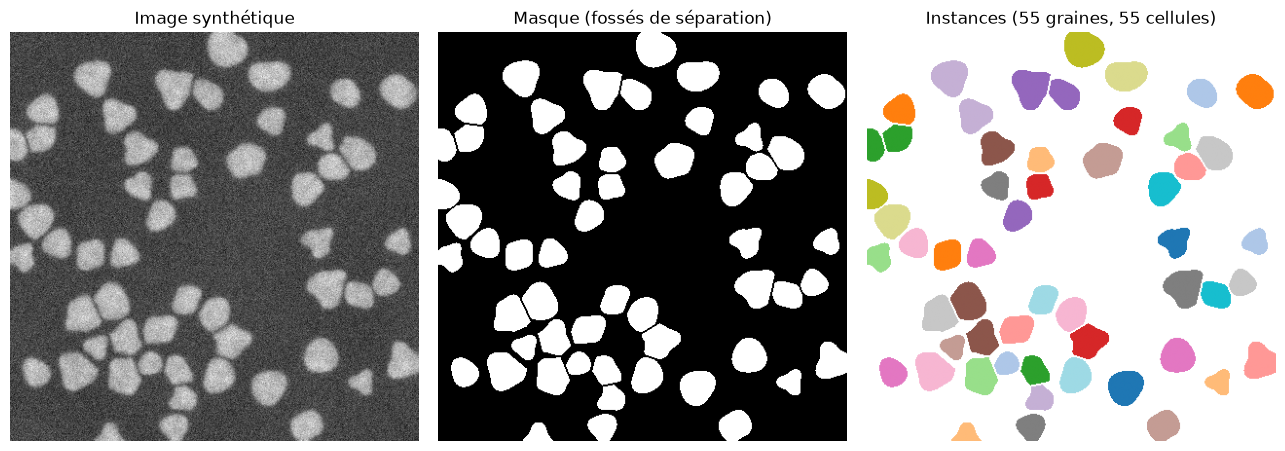

In [ ]:
def make_sample(rng, size=420, n_seeds=55, min_sep=26):
    """Retourne (image float32 [0,1], carte d'instances int32 avec fossés de séparation)."""
    pts = []
    for _ in range(4000):
        p = rng.uniform(0, size, 2)
        if all(np.hypot(*(p - q)) > min_sep for q in pts): pts.append(p)
        if len(pts) >= n_seeds: break
    pts = np.array(pts)
    r0 = rng.uniform(13, 21, len(pts))
    yy, xx = np.mgrid[0:size, 0:size]
    d, idx = cKDTree(pts).query(np.c_[yy.ravel(), xx.ravel()])
    idx = idx.reshape(size, size); d = d.reshape(size, size)
    ang = np.arctan2(yy - pts[idx, 0], xx - pts[idx, 1])
    k1, k2 = rng.integers(2, 4, len(pts)), rng.integers(3, 6, len(pts))
    ph1, ph2 = rng.uniform(0, 6.28, len(pts)), rng.uniform(0, 6.28, len(pts))
    a1, a2 = rng.uniform(0.05, 0.18, len(pts)), rng.uniform(0.02, 0.08, len(pts))
    rad = r0[idx] * (1 + a1[idx] * np.sin(k1[idx] * ang + ph1[idx]) + a2[idx] * np.sin(k2[idx] * ang + ph2[idx]))
    lab = np.where(d < rad, idx + 1, 0).astype(np.int32)
    lab[find_boundaries(lab, mode="inner")] = 0
    fg = lab > 0
    bg_noise = ndi.gaussian_filter(rng.normal(size=(size, size)), 25) * 6
    tex = ndi.gaussian_filter(rng.normal(size=(size, size)), 3) * 1.6
    img = 0.30 + 0.06 * bg_noise + np.where(fg, 0.30 + 0.12 * tex, 0.0)
    dist_in = ndi.distance_transform_edt(fg)
    img += np.where(fg, -0.18 * np.exp(-dist_in / 2.0), 0)           
    img += 0.08 * np.exp(-ndi.distance_transform_edt(~fg) / 2.0) * (~fg)  
    img = ndi.gaussian_filter(img, 1.0) + rng.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1).astype(np.float32), lab

rng = np.random.default_rng(1)
img, lab = make_sample(rng)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Image synthétique")
ax[1].imshow(lab > 0, cmap="gray"); ax[1].set_title("Masque (fossés de séparation)")
ax[2].imshow(np.ma.masked_equal(lab, 0) % 20, cmap="tab20"); ax[2].set_title(f"Instances ({lab.max()} graines, {len(np.unique(lab))-1} cellules)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Carte de poids de la perte 

$$w(x) = w_c(x) + w_0 \cdot \exp\!\left(-\frac{(d_1(x)+d_2(x))^2}{2\sigma^2}\right),\quad w_0 = 10,\ \sigma \approx 5\ \text{px}$$

- $w_c$ : équilibrage des fréquences de classes ;
- $d_1, d_2$ : distances aux bords de la cellule la plus proche et de la deuxième plus proche.

Les pixels de fond coincés entre deux cellules (où $d_1+d_2$ est petit) reçoivent un poids très élevé, ce qui force le réseau à apprendre ces fines frontières.
La perte est l'entropie croisée pondérée par pixel : $E=-\sum_x w(x)\log p_{\ell(x)}(x)$.

Calcul de la carte de poids : 0.67s


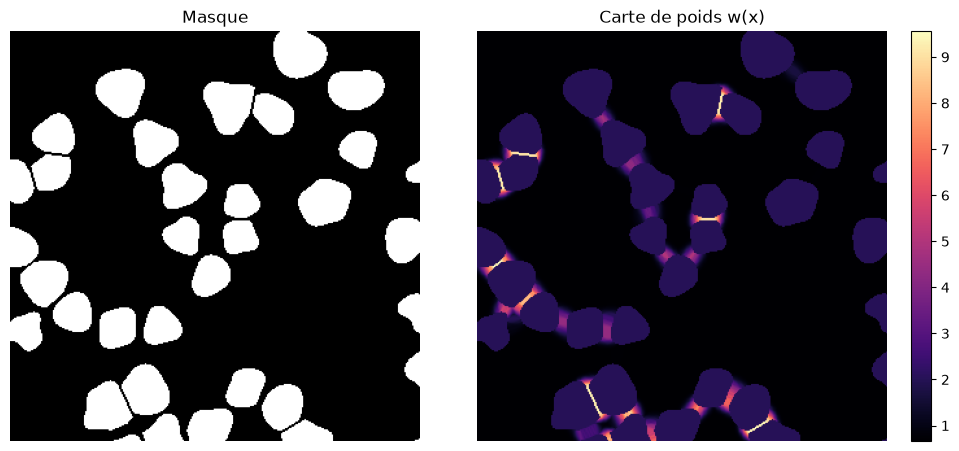

In [ ]:
def weight_map(lab, w0=10.0, sigma=5.0):
    fg = (lab > 0)
    
    n_fg, n_bg = fg.sum(), (~fg).sum()
    wc = np.where(fg, 0.5 * fg.size / max(n_fg, 1), 0.5 * fg.size / max(n_bg, 1)).astype(np.float32)
    wc /= wc.mean()
    ids = [i for i in np.unique(lab) if i != 0]
    if len(ids) < 2:
        return wc
    
    dists = np.stack([ndi.distance_transform_edt(lab != i) for i in ids])
    dists.sort(axis=0)
    d1, d2 = dists[0], dists[1]
    border = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
    return (wc + np.where(fg, 0, border)).astype(np.float32)   

t0 = time.time(); w = weight_map(lab[:316, :316]); print(f"Calcul de la carte de poids : {time.time()-t0:.2f}s")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
ax[0].imshow(lab[:316, :316] > 0, cmap="gray"); ax[0].set_title("Masque")
im = ax[1].imshow(w, cmap="magma"); ax[1].set_title("Carte de poids w(x)"); plt.colorbar(im, ax=ax[1], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Data augmentation par déformations élastiques 

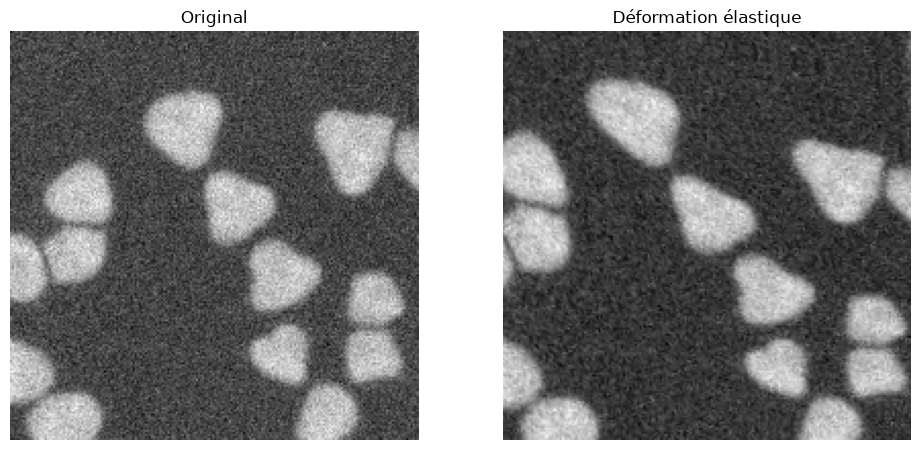

In [ ]:
def elastic_deform(arrays, orders, rng, grid=3, sigma=10.0):
    h, w = arrays[0].shape
    disp = rng.normal(0, sigma, size=(2, grid, grid))
    dense = np.stack([ndi.zoom(disp[i], (h / grid, w / grid), order=3, mode="nearest")[:h, :w] for i in range(2)]) 
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    coords = [yy + dense[0], xx + dense[1]]
    return [ndi.map_coordinates(a, coords, order=o, mode="reflect") for a, o in zip(arrays, orders)]

rng = np.random.default_rng(3)
im_d, lab_d = elastic_deform([img, lab.astype(np.float32)], [1, 0], rng)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
ax[0].imshow(img[:200, :200], cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(im_d[:200, :200], cmap="gray"); ax[1].set_title("Déformation élastique")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Jeu de données et pipeline d'entraînement


In [ ]:
rng_data = np.random.default_rng(123)
train_set = [make_sample(rng_data) for _ in range(30)]
test_set  = [make_sample(rng_data) for _ in range(10)]
print(f"{len(train_set)} images d'entraînement, {len(test_set)} images de test, taille {train_set[0][0].shape}")

MEAN, STD = 0.40, 0.20
def get_batch(rng, weighted=True):
    img, lab = train_set[rng.integers(len(train_set))]
    k = rng.integers(4); img, lab = np.rot90(img, k), np.rot90(lab, k)
    if rng.random() < 0.5: img, lab = img[:, ::-1], lab[:, ::-1]
    img, lab = elastic_deform([np.ascontiguousarray(img), np.ascontiguousarray(lab).astype(np.float32)], [1, 0], rng)
    y0, x0 = rng.integers(0, img.shape[0] - IN + 1, 2)
    img_c = img[y0:y0 + IN, x0:x0 + IN]
    lab_c = lab[y0:y0 + IN, x0:x0 + IN].astype(np.int32)
    m = (IN - OUT) // 2
    lab_o = lab_c[m:m + OUT, m:m + OUT]
    w = weight_map(lab_c)[m:m + OUT, m:m + OUT] if weighted else np.ones((OUT, OUT), np.float32)
    img_c = img_c * rng.uniform(0.9, 1.1) + rng.uniform(-0.05, 0.05)
    x = torch.from_numpy(((img_c - MEAN) / STD).astype(np.float32))[None, None]
    y = torch.from_numpy((lab_o > 0).astype(np.int64))[None]
    return x, y, torch.from_numpy(w)[None]

x, y, w = get_batch(np.random.default_rng(0))
print("x", tuple(x.shape), "| y", tuple(y.shape), "| w", tuple(w.shape), f"| w max = {w.max():.1f}")

30 images d'entraînement, 10 images de test, taille (420, 420)
x (1, 1, 316, 316) | y (1, 132, 132) | w (1, 132, 132) | w max = 4.4


In [ ]:
def train(weighted, steps, lr=1e-3, momentum=0.99, seed=0, log_every=25):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = UNet(base=BASE); model.train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum) 
    hist, run, t0 = [], 0.0, time.time()
    for it in range(1, steps + 1):
        x, y, w = get_batch(rng, weighted)
        logits = model(x)
        loss = (F.cross_entropy(logits, y, reduction="none") * w).mean()  
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        run += loss.item()
        if it % log_every == 0:
            hist.append((it, run / log_every)); run = 0.0
            if it % (log_every * 4) == 0:
                print(f"  [{'pondéré' if weighted else 'non pondéré'}] it {it:4d}/{steps} | loss {hist[-1][1]:.4f} | {time.time()-t0:.0f}s")
    return model.eval(), hist

_m = UNet(base=BASE); _o = torch.optim.SGD(_m.parameters(), lr=1e-3, momentum=0.99)
t0 = time.time()
for _ in range(3):
    x, y, w = get_batch(np.random.default_rng(1)); l = (F.cross_entropy(_m(x), y, reduction="none") * w).mean(); _o.zero_grad(); l.backward(); _o.step()
print(f"~{(time.time()-t0)/3:.2f} s / itération"); del _m, _o

~1.42 s / itération


## 6. Entraînement : perte pondérée (papier) vs perte non pondérée (ablation)



In [14]:
STEPS = 700
t0 = time.time()
model_w,  hist_w  = train(weighted=True,  steps=STEPS)
model_nw, hist_nw = train(weighted=False, steps=STEPS)
print(f"Durée totale d'entraînement : {(time.time()-t0)/60:.1f} min")

  [pondéré] it  100/700 | loss 0.2268 | 118s
  [pondéré] it  200/700 | loss 0.1070 | 235s
  [pondéré] it  300/700 | loss 0.0838 | 386s
  [pondéré] it  400/700 | loss 0.0594 | 529s
  [pondéré] it  500/700 | loss 0.0510 | 661s
  [pondéré] it  600/700 | loss 0.0594 | 801s
  [pondéré] it  700/700 | loss 0.0501 | 935s
  [non pondéré] it  100/700 | loss 0.1750 | 82s
  [non pondéré] it  200/700 | loss 0.0607 | 189s
  [non pondéré] it  300/700 | loss 0.0570 | 282s
  [non pondéré] it  400/700 | loss 0.0604 | 374s
  [non pondéré] it  500/700 | loss 0.0484 | 460s
  [non pondéré] it  600/700 | loss 0.0509 | 531s
  [non pondéré] it  700/700 | loss 0.0431 | 603s
Durée totale d'entraînement : 25.6 min


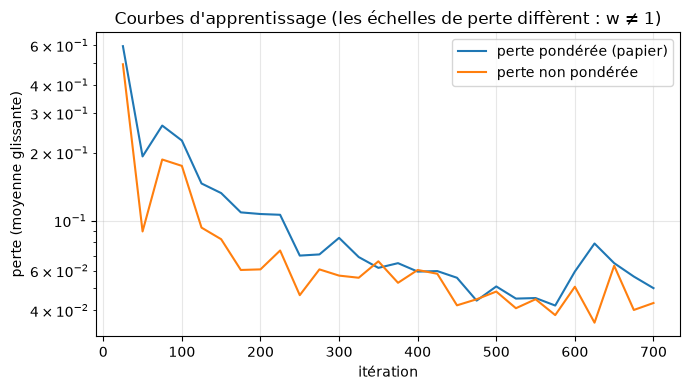

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(*zip(*hist_w), label="perte pondérée (papier)")
plt.plot(*zip(*hist_nw), label="perte non pondérée")
plt.xlabel("itération"); plt.ylabel("perte (moyenne glissante)"); plt.yscale("log"); plt.grid(alpha=.3); plt.legend()
plt.title("Courbes d'apprentissage (les échelles de perte diffèrent : w ≠ 1)")
plt.tight_layout(); plt.show()

## 7. Inférence par *overlap-tile* 



Inférence (2 modèles, image (420, 420)) : 9.5s


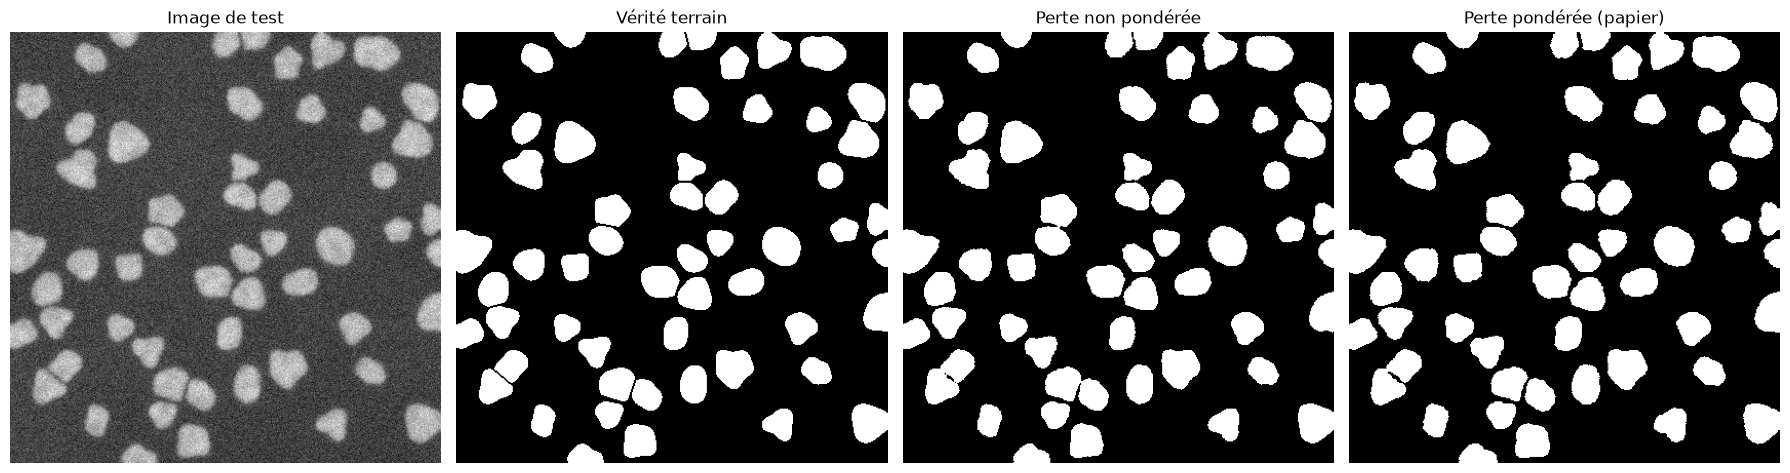

In [ ]:
@torch.no_grad()
def predict_tiled(model, img):
    H, W = img.shape
    m = (IN - OUT) // 2
    nH, nW = math.ceil(H / OUT), math.ceil(W / OUT)
    padH, padW = nH * OUT - H, nW * OUT - W
    p = np.pad(img, ((m, m + padH), (m, m + padW)), mode="reflect")      
    p = (p - MEAN) / STD
    prob = np.zeros((nH * OUT, nW * OUT), np.float32)
    for i in range(nH):
        for j in range(nW):
            tile = p[i * OUT:i * OUT + IN, j * OUT:j * OUT + IN]
            logit = model(torch.from_numpy(tile.astype(np.float32))[None, None])
            prob[i * OUT:(i + 1) * OUT, j * OUT:(j + 1) * OUT] = F.softmax(logit, 1)[0, 1].numpy()
    return prob[:H, :W]

img_t, lab_t = test_set[0]
t0 = time.time(); prob_w = predict_tiled(model_w, img_t); prob_nw = predict_tiled(model_nw, img_t)
print(f"Inférence (2 modèles, image {img_t.shape}) : {time.time()-t0:.1f}s")
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
ax[0].imshow(img_t, cmap="gray"); ax[0].set_title("Image de test")
ax[1].imshow(lab_t > 0, cmap="gray"); ax[1].set_title("Vérité terrain")
ax[2].imshow(prob_nw > .5, cmap="gray"); ax[2].set_title("Perte non pondérée")
ax[3].imshow(prob_w > .5, cmap="gray"); ax[3].set_title("Perte pondérée (papier)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 8. Évaluation quantitative



In [17]:
def pixel_metrics(pred, gt):
    inter = (pred & gt).sum(); union = (pred | gt).sum()
    return inter / union, 2 * inter / (pred.sum() + gt.sum()), (pred == gt).mean()

def instance_metrics(pred_mask, lab):
    pl, n_pred = ndi.label(pred_mask)
    gt_ids = [i for i in np.unique(lab) if i]
    tp, merged_comp = 0, 0
    for i in gt_ids:
        g = lab == i
        ov = np.bincount(pl[g], minlength=n_pred + 1); ov[0] = 0
        if ov.max() == 0: continue
        j = ov.argmax()
        if ov[j] / ((pl == j).sum() + g.sum() - ov[j]) > 0.5: tp += 1
    for j in range(1, n_pred + 1):                                   # composantes couvrant >=2 cellules
        ids = np.unique(lab[pl == j]); ids = ids[ids > 0]
        cover = [(lab[pl == j] == i).sum() / (lab == i).sum() for i in ids]
        if sum(c > 0.5 for c in cover) >= 2: merged_comp += 1
    prec = tp / max(n_pred, 1); rec = tp / max(len(gt_ids), 1)
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-9), merged_comp, len(gt_ids)

rows = {"pondérée (papier)": [], "non pondérée": []}
for name, mdl in [("pondérée (papier)", model_w), ("non pondérée", model_nw)]:
    for im_, lb_ in test_set:
        pr = predict_tiled(mdl, im_) > 0.5
        iou, dice, acc = pixel_metrics(pr, lb_ > 0)
        p, r, f1, mrg, n = instance_metrics(pr, lb_)
        rows[name].append([iou, dice, acc, p, r, f1, mrg, n])
cols = ["IoU px", "Dice px", "Acc px", "Préc. inst.", "Rappel inst.", "F1 inst.", "Fusions", "# cellules"]
print(f"{'Perte':<20}" + "".join(f"{c:>13}" for c in cols[:6]) + f"{'Fusions/img':>13}")
for name, v in rows.items():
    v = np.array(v); mu = v.mean(0)
    print(f"{name:<20}" + "".join(f"{x:>13.3f}" for x in mu[:6]) + f"{mu[6]:>13.2f}")
summary = {k: np.array(v).mean(0) for k, v in rows.items()}

Perte                      IoU px      Dice px       Acc px  Préc. inst. Rappel inst.     F1 inst.  Fusions/img
pondérée (papier)           0.927        0.962        0.981        0.993        0.991        0.992         0.30
non pondérée                0.962        0.981        0.991        0.979        0.907        0.941         3.70


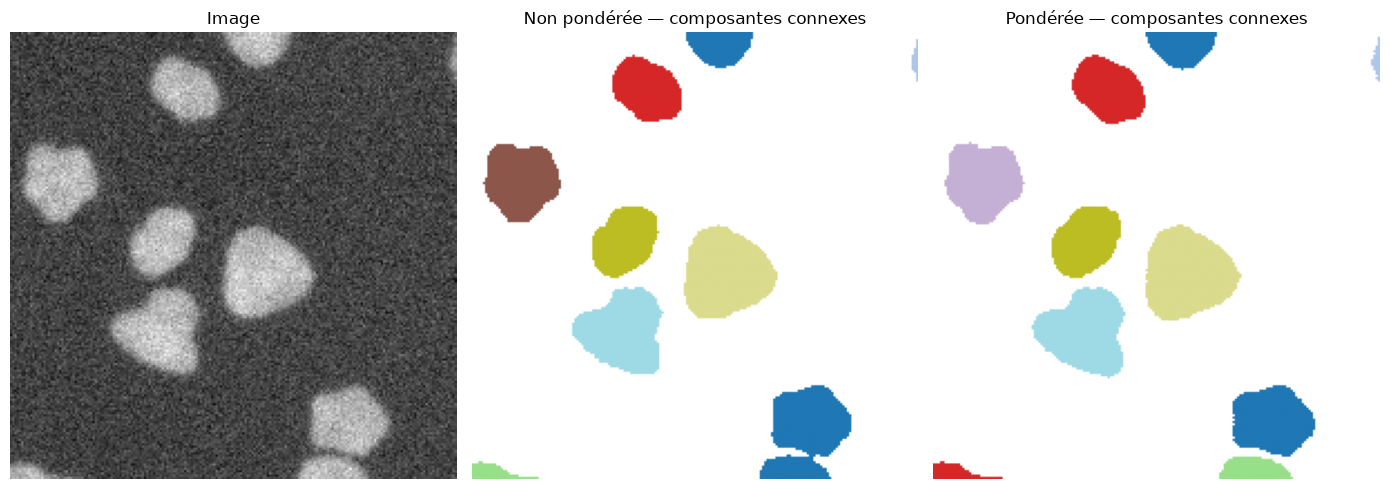

In [ ]:
sub = (slice(0, 200), slice(0, 200))
fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
ax[0].imshow(img_t[sub], cmap="gray"); ax[0].set_title("Image")
for a, p, t in [(ax[1], prob_nw, "Non pondérée"), (ax[2], prob_w, "Pondérée")]:
    pl, _ = ndi.label(p > .5)
    a.imshow(np.ma.masked_equal(pl[sub], 0) % 20, cmap="tab20"); a.set_title(f"{t} — composantes connexes")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()